# Modeling Experiments

We perform some modeling experiments using various models. In the modeling experiment process, we only use the training set that we had obtained from earlier to do our work. 
We avoid peaking on the test set in [data/cleaned_data/test.csv](data/cleaned_data/test.csv). We perform analysis of the most relevant features as we proceed in the modeling experiments and continue with exploratory data analysis.

Our original base line model in [models/modeling_baselines.ipynb](models/modeling_baselines.ipynb) utilized the training and test split there. Here we take that training set and had it split into a new training set and a new validation set since we not want to peak at our final evaluation metric. The baseline model we had originally was a Logistic Regression model. It had limited feature engineering and did not utilize any informed imputation methods.

In [61]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, log_loss, 
                             classification_report, average_precision_score, precision_recall_curve)




import warnings
warnings.filterwarnings("ignore")

# Feature Engineering Function

This section has a function designed to add features to the data set. These features are informed by EDA and domain specific knowledge regarding diabetes.

In [146]:
def add_features(df):
    # add features for dataframe here
    return df

# Train/Validation Split and Import Data

In [ ]:
# # Import the cleaned_data

# train = pd.read_csv("../data/cleaned_data/train.csv")
# X = train.drop(columns="target")
# y = train["target"]

In [ ]:
# # The target is imbalanced. We also want to keep repeat patients together.

# # 1. Set n_splits=5 so the test size naturally becomes 1/5 = 20%
# sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# # 2. Get the indices for the very first split next() gets only the first split for us
# train_idx, test_idx = next(sgkf.split(X, y, groups=X['patient_nbr']))

# # 3. Create a single train/test split
# Xt, Xv = X.iloc[train_idx], X.iloc[test_idx]
# yt, yv = y.iloc[train_idx], y.iloc[test_idx]


# # We will save the train / validation split here and use it for the modeling experiments

# train = Xt.copy()
# train["target"] = yt
# train.to_csv("modeling_data/train.csv",index=False)

# validation = Xv.copy()
# validation["target"] = yv 
# validation.to_csv("modeling_data/validation.csv",index=False)


In [77]:
# In the previous code chunk, we have commented out the train/validation split-up of our training data.

# Below is the code to import that data

# Xt = pd.read_csv("modeling_data/train.csv")
# yt = Xt["target"]
# Xt.drop(columns=["target"],inplace=True)
# Xv = pd.read_csv("modeling_data/validation.csv")
# yv = Xv["target"]
# Xv.drop(columns=["target"],inplace=True)


# XGBoost Classifier

For helpful information regarding XGBoost Classifier, see https://xgboosting.com/

In [ ]:
# import xgboost
import xgboost as xgb

Xt = pd.read_csv("modeling_data/train.csv")
yt = Xt["target"]
Xt.drop(columns=["target"],inplace=True)
Xv = pd.read_csv("modeling_data/validation.csv")
yv = Xv["target"]
Xv.drop(columns=["target"],inplace=True)

Xt.drop(columns=["patient_nbr"],inplace=True)
Xv.drop(columns=["patient_nbr"],inplace=True)


In [73]:
# Define XGBClassifier model parameters

spw = (yt == 0).sum() / (yt == 1).sum()   

params = {
    'objective': 'binary:logistic',
    'max_depth': 6,
    'learning_rate': 0.05,
    'n_estimators': 2_500,
    'subsample': 0.1,
    'enable_categorical': True,
    'colsample_bytree': 0.1,
    'scale_pos_weight': spw, # this deals with the class inbalance issue
    'random_state': 42,
}

num_cols = Xt.select_dtypes(include=["number", "bool"]).columns
cat_cols = [c for c in Xt.columns if c not in num_cols]

# Drop columns that are constant in training (decided from training only)
const_cols = [c for c in cat_cols if Xt[c].nunique(dropna=False) <= 1]
Xt = Xt.drop(columns=const_cols)
Xv = Xv.drop(columns=const_cols)
cat_cols = [c for c in cat_cols if c not in const_cols]

# Categories come from the training set; unseen levels in Xv become NaN
Xt = Xt.copy()
Xv = Xv.copy()
for c in cat_cols:
    dtype = pd.CategoricalDtype(categories=Xt[c].dropna().unique())
    Xt[c] = Xt[c].astype(dtype)
    Xv[c] = Xv[c].astype(dtype)

# Instantiate XGBClassifier with the parameters
model = xgb.XGBClassifier(**params)

# Train the model
model.fit(Xt, yt)

# Make predictions on the test set
y_pred = model.predict(Xv)

# Evaluate model performance
accuracy = accuracy_score(yv, y_pred)
confusion = confusion_matrix(yv, y_pred)
report = classification_report(yv, y_pred)

print(f"Accuracy: {accuracy:.2f}\n")
print(f"Confusion Matrix:\n{confusion}\n")
print(f"Classification Report:\n{report}\n")
f1 = f1_score(yv, y_pred, zero_division=0)
print(f"F1-Score: {np.round(f1,3)}")

Accuracy: 0.65

Confusion Matrix:
[[9663 4803]
 [ 853  964]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.67      0.77     14466
           1       0.17      0.53      0.25      1817

    accuracy                           0.65     16283
   macro avg       0.54      0.60      0.51     16283
weighted avg       0.84      0.65      0.72     16283


F1-Score: 0.254


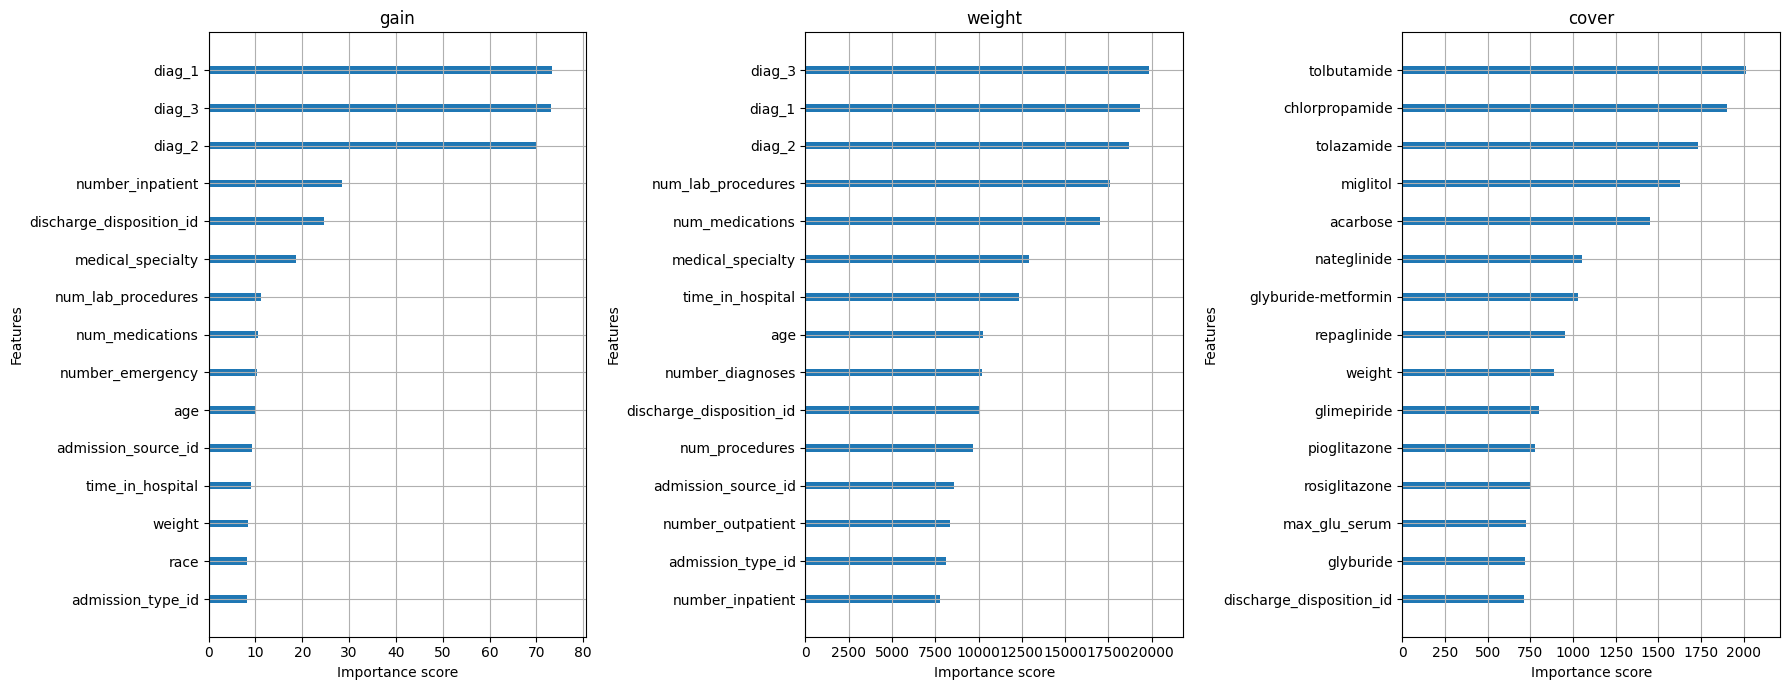

In [74]:
import xgboost as xgb
import matplotlib.pyplot as plt


fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, t in zip(axes, ["gain", "weight", "cover"]):
    xgb.plot_importance(model, importance_type=t, max_num_features=15,
                        ax=ax, title=t, show_values=False)
plt.tight_layout()
plt.show()

# Logistic Regression Again

In [183]:
Xt = pd.read_csv("modeling_data/train.csv")
yt = Xt["target"]
Xt.drop(columns=["target"],inplace=True)
Xv = pd.read_csv("modeling_data/validation.csv")
yv = Xv["target"]
Xv.drop(columns=["target"],inplace=True)

Xt = add_features(Xt)
Xv = add_features(Xv)

Xt.drop(columns=["patient_nbr"],inplace=True)
Xv.drop(columns=["patient_nbr"],inplace=True)

In [184]:
# num_cols = Xt.select_dtypes(include=['int64', 'float64']).columns.tolist()
# cat_cols = Xt.select_dtypes(include=['object','category']).columns.tolist()
# features = num_cols+cat_cols

# print(num_cols)
# print(cat_cols)

In [185]:
# Detailed Feature Selection on Numerical Columns

num_cols = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_diagnoses', 'number_inpatient', ]

# Detailed Feature Selection on Categorical Columns
cat_cols = ['diag_1', 'diag_2','diag_3','medical_specialty', 'age', 'tolbutamide', 'chlorpropamide', 'discharge_disposition_id', 'medical_specialty']

In [186]:
# We use pipelines to make the feature selection and data cleaning process quicker

num = Pipeline([("imp", SimpleImputer(strategy="median")),("scale", StandardScaler())])
cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",min_frequency=20))])
prep = ColumnTransformer([("num", num, num_cols),("cat", cat, cat_cols)])
clf = Pipeline([("prep", prep), ("model", LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.75, C=0.5, class_weight="balanced", max_iter=1250, random_state=42))])


In [187]:
# Fit the model to the training data
clf.fit(Xt,yt)

# Have the model now make predictions
labels = clf.predict(Xv)

In [188]:
probs = clf.predict_proba(Xv)
p = probs[:, 1]

# Analyze the accuracy, roc_auc, log_loss, precision, recall, F1-score. We also can look at the confusion matrix.

acc = accuracy_score(yv, labels)
auc = roc_auc_score(yv, p)               
loss = log_loss(yv, probs, labels=[0,1])

threshold = 0.13

custom = (p >= threshold).astype(int)
precision = precision_score(yv, custom, zero_division=0)
recall = recall_score(yv, custom, zero_division=0)
f1 = f1_score(yv, custom, zero_division=0)

tn, fp, fn, tp = confusion_matrix(yv, custom, labels=[0, 1]).ravel()

print(f"The results of the baseline model is:") 
print(f"Accuracy: {np.round(acc,3)}")
print(f"AUC: {np.round(auc,3)}")
print(f"Log Loss: {np.round(loss,3)}\n\n")
print(f"Assuming a threshold of p={threshold}:")
print(f"Precision: {np.round(precision,3)}")
print(f"Recall: {np.round(recall,3)}")
print(f"F1-Score: {np.round(f1,5)}")


# Best-threshold F1 (optimistic: threshold chosen on Xv itself)
p, r, thr = precision_recall_curve(yv, p)
f1s = 2 * p * r / (p + r + 1e-12)
best = f1s[:-1].argmax()
print(f"Best-threshold F1: {f1s[best]:.3f} at threshold {thr[best]:.3f}")

The results of the baseline model is:
Accuracy: 0.659
AUC: 0.659
Log Loss: 0.635


Assuming a threshold of p=0.13:
Precision: 0.114
Recall: 0.998
F1-Score: 0.20518
Best-threshold F1: 0.278 at threshold 0.551


# CatBoost

We consider a catboost model.

In [147]:
# import catboost

from catboost import CatBoostClassifier

# Reimport the data since we want to be able to change our experiments individually.
Xt = pd.read_csv("modeling_data/train.csv")
yt = Xt["target"]
Xt.drop(columns=["target"],inplace=True)
Xv = pd.read_csv("modeling_data/validation.csv")
yv = Xv["target"]
Xv.drop(columns=["target"],inplace=True)

# Xt = add_features(Xt)
# Xv = add_features(Xv)

Xt.drop(columns=["patient_nbr"],inplace=True)
Xv.drop(columns=["patient_nbr"],inplace=True)

In [150]:
# prepare for catboost
num_cols = Xt.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in Xt.columns if c not in num_cols]


# careful!! catboost demands categorical columns to have string entry
Xt_cb, Xv_cb = Xt.copy(), Xv.copy()
for c in cat_cols:
    for df in (Xt_cb, Xv_cb):
        df[c] = df[c].astype(object).where(df[c].notna(), "missing").astype(str)


# fitting to the training set, we determine the scale positive weight
# it resolves the class imbalance 
spw = (yt == 0).sum() / (yt == 1).sum()

model = CatBoostClassifier(
    iterations=1_000, # choose a slightly high number of iterations due to no feature selection
    learning_rate=0.05,
    depth=5, 
    l2_leaf_reg=2, # l2 regularization to shift weights closer to 0
    scale_pos_weight=spw, # this handles class imbalance
    random_seed=42,
    verbose=50, # choose verbose to print every 100 iterations
    loss_function="Logloss",
    task_type="GPU",
    devices="0",
    eval_metric="Logloss:use_weights=false",
)
model.fit(Xt_cb, yt, cat_features=cat_cols)

0:	learn: 0.6890616	total: 39.4ms	remaining: 39.3s
50:	learn: 0.6418508	total: 1.89s	remaining: 35.1s
100:	learn: 0.6347594	total: 3.63s	remaining: 32.3s
150:	learn: 0.6304469	total: 5.34s	remaining: 30.1s
200:	learn: 0.6263490	total: 7.11s	remaining: 28.2s
250:	learn: 0.6228935	total: 8.99s	remaining: 26.8s
300:	learn: 0.6195347	total: 10.8s	remaining: 25.1s
350:	learn: 0.6162731	total: 12.5s	remaining: 23.2s
400:	learn: 0.6129827	total: 14.3s	remaining: 21.4s
450:	learn: 0.6096930	total: 16.2s	remaining: 19.7s
500:	learn: 0.6066802	total: 18.2s	remaining: 18.1s
550:	learn: 0.6039186	total: 20.1s	remaining: 16.4s
600:	learn: 0.6008479	total: 22.2s	remaining: 14.7s
650:	learn: 0.5981641	total: 24.1s	remaining: 12.9s
700:	learn: 0.5954223	total: 26s	remaining: 11.1s
750:	learn: 0.5927721	total: 27.8s	remaining: 9.23s
800:	learn: 0.5902054	total: 29.7s	remaining: 7.38s
850:	learn: 0.5877155	total: 31.6s	remaining: 5.54s
900:	learn: 0.5851108	total: 33.5s	remaining: 3.68s
950:	learn: 0.58

CatBoostClassifier(depth=5, devices='0', eval_metric='Logloss:use_weights=false', iterations=1000, l2_leaf_reg=2, learning_rate=0.05, loss_function='Logloss', random_seed=42, scale_pos_weight=7.9610621904237755, task_type='GPU', verbose=50)

In [198]:
proba = model.predict_proba(Xv_cb)[:, 1]
threshold = 0.58
y_pred = (proba >= threshold).astype(int)

print("ROC-AUC:", round(roc_auc_score(yv, proba), 4))
print("PR-AUC: ", round(average_precision_score(yv, proba), 4))
print(f"Accuracy: {accuracy_score(yv, y_pred):.3f}")
print("\nConfusion matrix:\n", confusion_matrix(yv, y_pred))
print(f"\n\n{classification_report(yv, y_pred)}")
print(f"\nF1 @{threshold}: {round(f1_score(yv,y_pred),4)}")

# Best-threshold F1 (optimistic: threshold chosen on Xv itself)
p, r, thr = precision_recall_curve(yv, proba)
f1s = 2 * p * r / (p + r + 1e-12)
best = f1s[:-1].argmax()
print(f"\nBest-threshold F1: {f1s[best]:.4f} at threshold {thr[best]:.4f}")

ROC-AUC: 0.6828
PR-AUC:  0.2337
Accuracy: 0.783

Confusion matrix:
 [[12024  2442]
 [ 1092   725]]


              precision    recall  f1-score   support

           0       0.92      0.83      0.87     14466
           1       0.23      0.40      0.29      1817

    accuracy                           0.78     16283
   macro avg       0.57      0.62      0.58     16283
weighted avg       0.84      0.78      0.81     16283


F1 @0.58: 0.2909

Best-threshold F1: 0.2914 at threshold 0.5806


# LightGBM

In [ ]:
import lightgbm as lgb 

# import lightgbm

# Reimport the data since we want to be able to change our experiments individually.
Xt = pd.read_csv("modeling_data/train.csv")
yt = Xt["target"]
Xt.drop(columns=["target"],inplace=True)
Xv = pd.read_csv("modeling_data/validation.csv")
yv = Xv["target"]
Xv.drop(columns=["target"],inplace=True)
Xt.drop(columns=["patient_nbr"],inplace=True)
Xv.drop(columns=["patient_nbr"],inplace=True)

In [ ]:
# prepare for lgb
num_cols = Xt.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in Xt.columns if c not in num_cols]

Xt_lgb, Xv_lgb = Xt.copy(), Xv.copy()
for c in cat_cols:
    dtype = pd.CategoricalDtype(categories=Xt[c].dropna().astype(str).unique())
    Xt_lgb[c] = Xt[c].astype(str).astype(dtype)
    Xv_lgb[c] = Xv[c].astype(str).astype(dtype)


const = [c for c in Xt.columns if Xt[c].nunique(dropna=False) <= 1]

# near-constant: >99.5% one value
near_const = [c for c in Xt.columns
              if Xt[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.995]

model = lgb.LGBMClassifier(
    n_estimators= 1_000,
    learning_rate=0.05,
    num_leaves=35,
    min_child_samples=50,
    subsample=0.8, 
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=15,
    cat_smooth=65,          # regularizes rare category levels
    min_data_per_group=1_000, # ensure enough data per group is used 
    is_unbalance=True,   # do this instead of spw
    random_state=42,
    verbose=-1,
)
model.fit(Xt_lgb, yt)   # pandas 'category' columns are detected automatically

,boosting_type,'gbdt'
,num_leaves,35
,max_depth,-1
,learning_rate,0.05
,n_estimators,1000
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,50


In [ ]:
# Check feature importance
imp = pd.Series(model.booster_.feature_importance(importance_type="gain"),
                index=Xt_lgb.columns).sort_values(ascending=False)

print(f"Top Ten Most Important Features by Gain")
print(imp[0:10])

Top Ten Most Important Features by Gain
diag_1                      120870.609445
diag_3                      100332.940506
diag_2                       98972.139532
num_lab_procedures           83714.637838
num_medications              63666.589182
number_inpatient             53125.068430
time_in_hospital             42187.479298
discharge_disposition_id     40249.730412
age                          27547.432891
medical_specialty            26022.041833
dtype: float64


In [ ]:
proba = model.predict_proba(Xv_lgb)[:, 1]
y_pred = (proba >= 0.5).astype(int)

print("ROC-AUC:", round(roc_auc_score(yv, proba), 4))
print("PR-AUC: ", round(average_precision_score(yv, proba), 4))
print(f"Accuracy: {accuracy_score(yv, y_pred):.3f}")
print("Confusion matrix:\n", confusion_matrix(yv, y_pred))
print(classification_report(yv, y_pred))
print("F1 @0.5:", round(f1_score(yv, y_pred), 3))

p, r, thr = precision_recall_curve(yv, proba)
f1s = 2 * p * r / (p + r + 1e-12)
best = f1s[:-1].argmax()
print(f"Best-threshold F1: {f1s[best]:.3f} at threshold {thr[best]:.3f} (optimistic: chosen on Xv)")

ROC-AUC: 0.6639
PR-AUC:  0.2131
Accuracy: 0.769
Confusion matrix:
 [[11844  2622]
 [ 1140   677]]
              precision    recall  f1-score   support

           0       0.91      0.82      0.86     14466
           1       0.21      0.37      0.26      1817

    accuracy                           0.77     16283
   macro avg       0.56      0.60      0.56     16283
weighted avg       0.83      0.77      0.80     16283

F1 @0.5: 0.265
Best-threshold F1: 0.271 at threshold 0.470 (optimistic: chosen on Xv)


# RandomForest Classifier

In [165]:
from sklearn.ensemble import RandomForestClassifier

# import the random forest classifier

Xt = pd.read_csv("modeling_data/train.csv")
yt = Xt["target"]
Xt.drop(columns=["target"],inplace=True)
Xv = pd.read_csv("modeling_data/validation.csv")
yv = Xv["target"]
Xv.drop(columns=["target"],inplace=True)

Xt = add_features(Xt)
Xv = add_features(Xv)

Xt.drop(columns=["patient_nbr"],inplace=True)
Xv.drop(columns=["patient_nbr"],inplace=True)

num_cols = Xt.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = Xt.select_dtypes(include=['object','category']).columns.tolist()
features = num_cols+cat_cols


In [166]:
# We use pipelines to make the feature selection and data cleaning process quicker

num = Pipeline([("imp", SimpleImputer(strategy="median")),("scale", StandardScaler())])
cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",min_frequency=20))])
prep = ColumnTransformer([("num", num, num_cols),("cat", cat, cat_cols)])
clf = Pipeline([("prep", prep), ("model", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced'))])


In [167]:
# Fit the model to the training data
clf.fit(Xt,yt)

# Have the model now make predictions
labels = clf.predict(Xv)

In [174]:
probs = clf.predict_proba(Xv)
p = probs[:, 1]

# Analyze the accuracy, roc_auc, log_loss, precision, recall, F1-score. We also can look at the confusion matrix.

acc = accuracy_score(yv, labels)
auc = roc_auc_score(yv, p)               
loss = log_loss(yv, probs, labels=[0,1])

threshold = 0.25

custom = (p >= threshold).astype(int)
precision = precision_score(yv, custom, zero_division=0)
recall = recall_score(yv, custom, zero_division=0)
f1 = f1_score(yv, custom, zero_division=0)

tn, fp, fn, tp = confusion_matrix(yv, custom, labels=[0, 1]).ravel()

print(f"The results of the baseline model is:") 
print(f"Accuracy: {np.round(acc,3)}")
print(f"AUC: {np.round(auc,3)}")
print(f"Log Loss: {np.round(loss,3)}\n\n")
print(f"Assuming a threshold of p={threshold}:")
print(f"Precision: {np.round(precision,3)}")
print(f"Recall: {np.round(recall,3)}")
print(f"F1-Score: {np.round(f1,5)}")




# Best-threshold F1 (optimistic: threshold chosen on Xv itself)
p, r, thr = precision_recall_curve(yv, p)
f1s = 2 * p * r / (p + r + 1e-12)
best = f1s[:-1].argmax()
print(f"Best-threshold F1: {f1s[best]:.3f} at threshold {thr[best]:.3f}")

The results of the baseline model is:
Accuracy: 0.889
AUC: 0.66
Log Loss: 0.335


Assuming a threshold of p=0.25:
Precision: 0.338
Recall: 0.121
F1-Score: 0.17769
Best-threshold F1: 0.272 at threshold 0.160


# Conclusions

So far, it seems like CatBoost is able to provide the best F1-Scores at threshold p=0.58.